In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

plt.style.use('default')
sns.set(font_scale=1.1, palette='husl')

In [22]:
# Load & prep data
df = pd.read_csv("global air pollution dataset.csv")
num_cols = ["AQI Value", "CO AQI Value", "Ozone AQI Value", "NO2 AQI Value", "PM2.5 AQI Value"]
for col in num_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

print(f"Dataset loaded: {df.shape[0]:,} records, {df['Country'].nunique()} countries, {df['City'].nunique()} cities")

Dataset loaded: 23,463 records, 175 countries, 23462 cities



 TOP 5 WORST CITIES:
Country  City   
India    Aonla      500.0
         Bagar      500.0
         Bahjoi     500.0
         Balotra    500.0
         Bareli     500.0
Name: AQI Value, dtype: float64

 TOP 5 CLEANEST CITIES:
Country                           City    
Bolivia (Plurinational State of)  El Torno    6.0
Ecuador                           Macas       7.0
                                  Azogues     8.0
Papua New Guinea                  Tari        8.0
Peru                              Huaraz      9.0
Name: AQI Value, dtype: float64


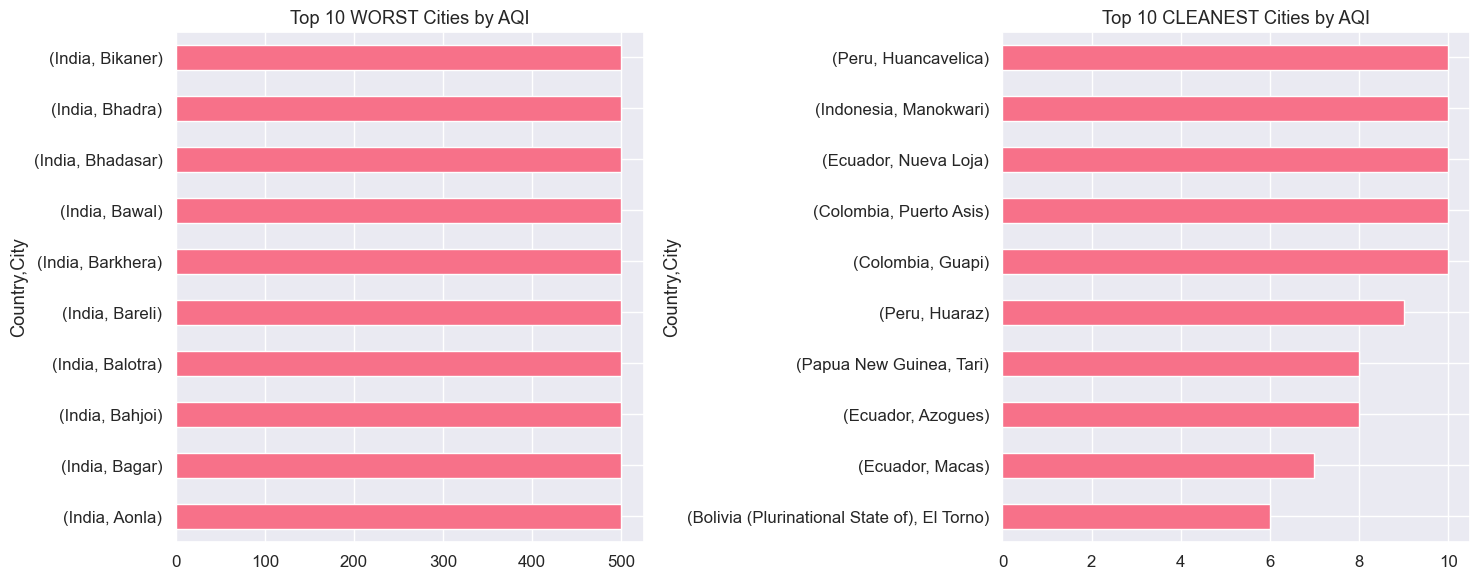

In [23]:
# 1. WORST & BEST CITIES BY AQI
#Question: Which cities have the worst and best overall air quality (AQI Value)?
city_aqi = df.groupby(["Country", "City"])["AQI Value"].mean().round(1)

print("\n TOP 5 WORST CITIES:")
print(city_aqi.nlargest(5))
print("\n TOP 5 CLEANEST CITIES:")
print(city_aqi.nsmallest(5))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
city_aqi.nlargest(10).plot(kind='barh', ax=axes[0])
axes[0].set_title("Top 10 WORST Cities by AQI")
city_aqi.nsmallest(10).plot(kind='barh', ax=axes[1])
axes[1].set_title("Top 10 CLEANEST Cities by AQI")
plt.tight_layout()
plt.show()

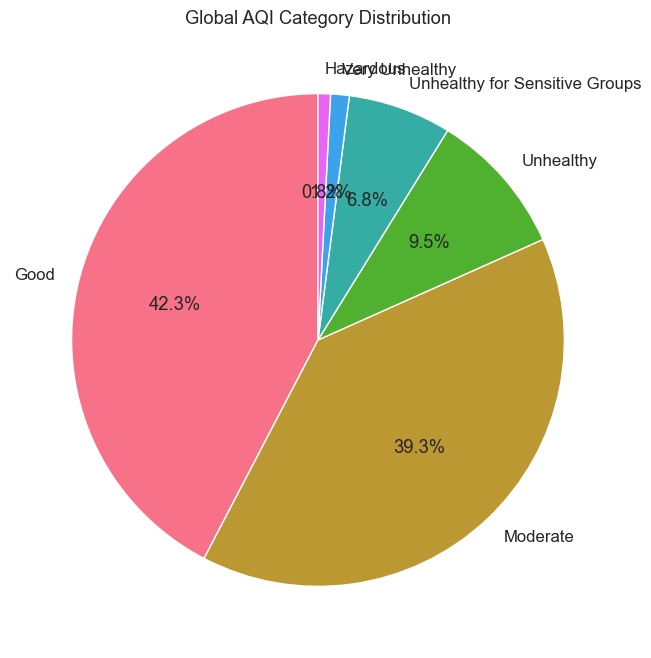

In [24]:
# 2. AQI CATEGORY DISTRIBUTION
#Question: How are cities distributed across AQI categories (Good, Moderate, Unhealthy, etc.) globally?
cat_counts = df["AQI Category"].value_counts()
plt.figure(figsize=(8, 8))
plt.pie(cat_counts.values, labels=cat_counts.index, autopct='%1.1f%%', startangle=90)
plt.title("Global AQI Category Distribution")
plt.show()

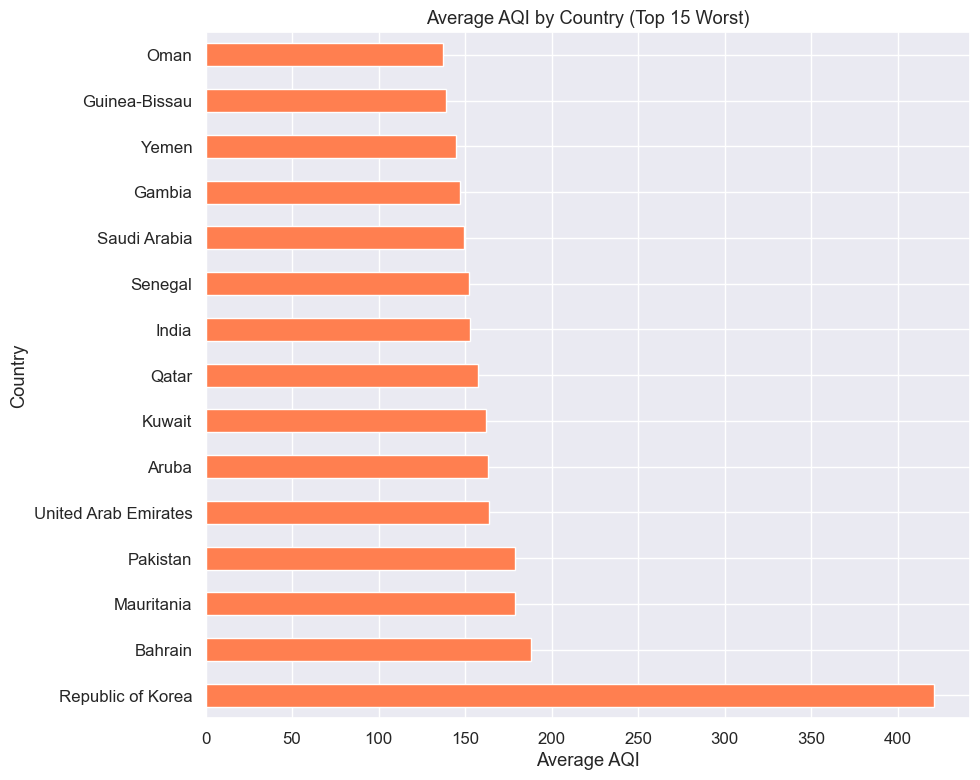

In [25]:
# 3. COUNTRY-WISE AVERAGE AQI
#Question: What is the average AQI Value per country?
country_aqi = df.groupby("Country")["AQI Value"].mean().sort_values(ascending=False).round(1)
country_aqi.head(15).plot(kind='barh', figsize=(10, 8), color='coral')
plt.xlabel("Average AQI")
plt.title("Average AQI by Country (Top 15 Worst)")
plt.tight_layout()
plt.show()

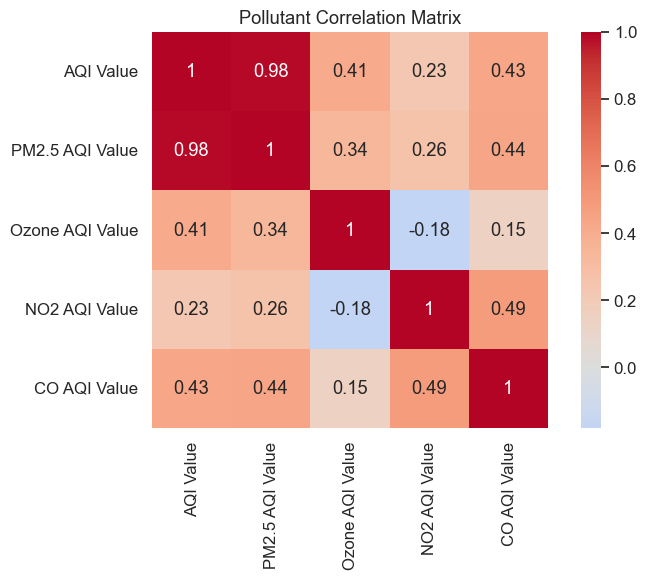

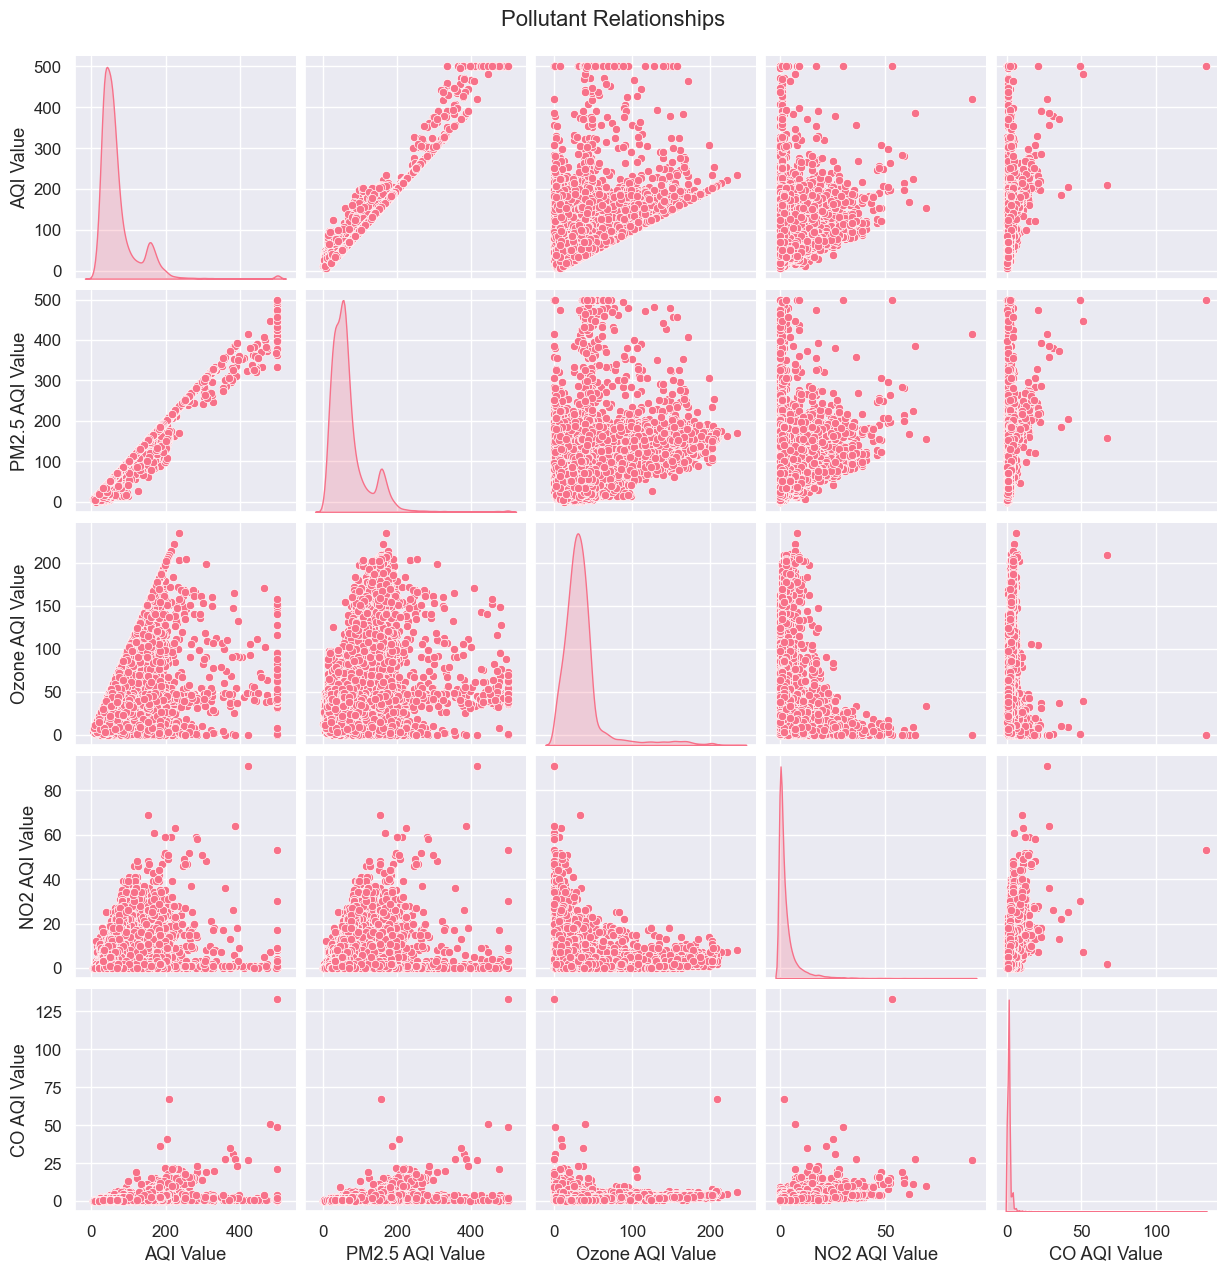

In [26]:
# 4. CORRELATION BETWEEN POLLUTANTS
#Question: How do CO, Ozone, NO2, and PM2.5 values correlate with overall AQI?
poll_cols = ["AQI Value", "PM2.5 AQI Value", "Ozone AQI Value", "NO2 AQI Value", "CO AQI Value"]
corr_matrix = df[poll_cols].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, square=True)
plt.title("Pollutant Correlation Matrix")
plt.tight_layout()
plt.show()

# Pairplot
sns.pairplot(df[poll_cols].dropna(), diag_kind='kde')
plt.suptitle("Pollutant Relationships", y=1.02)
plt.show()

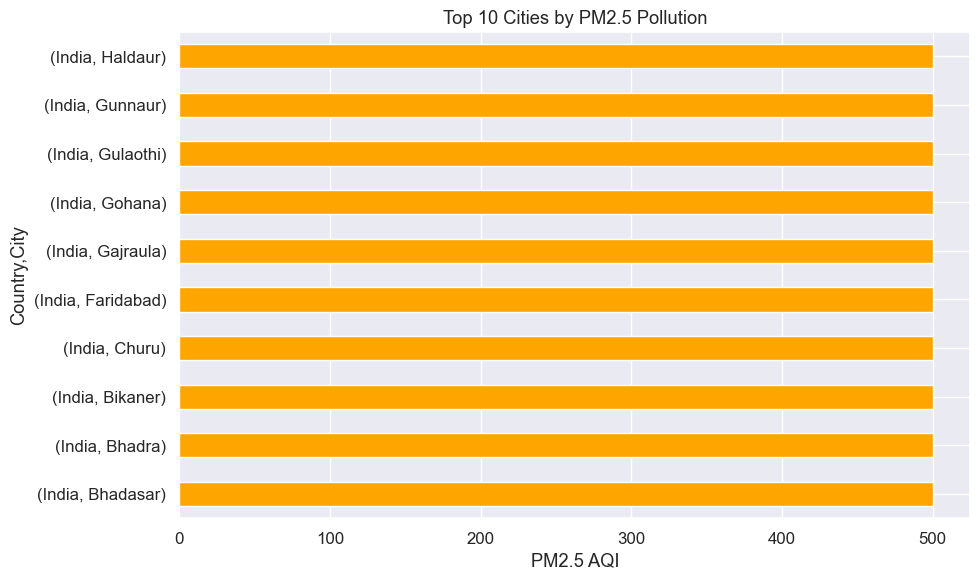

In [27]:
# 5. HIGHEST PM2.5 CITIES
#Question: Which cities have the highest PM2.5 AQI values?
pm25_top = df.groupby(["Country", "City"])["PM2.5 AQI Value"].mean().nlargest(10)
pm25_top.plot(kind='barh', figsize=(10, 6), color='orange')
plt.xlabel("PM2.5 AQI")
plt.title("Top 10 Cities by PM2.5 Pollution")
plt.tight_layout()
plt.show()

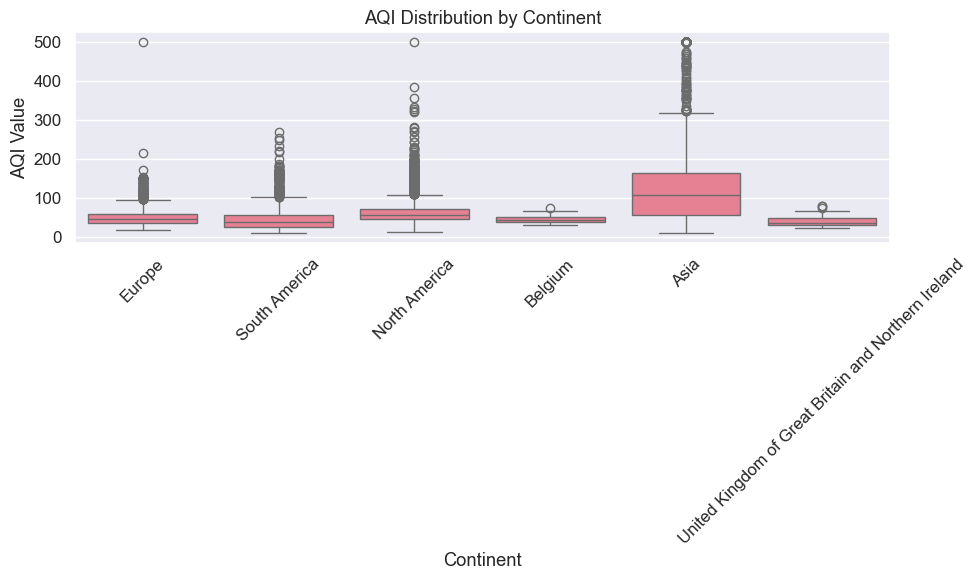

In [28]:
# 6. REGIONAL TRENDS (Using country → continent mapping)
#Question: Are there regional trends in AQI? (e.g., Asia vs Europe vs Americas) Visualization: Box plot of AQI Value by continent/region.
continent_map = {
    'India':'Asia', 'China':'Asia', 'Pakistan':'Asia', 'Bangladesh':'Asia', 'Indonesia':'Asia',
    'Japan':'Asia', 'Philippines':'Asia', 'Thailand':'Asia', 'Vietnam':'Asia', 'Myanmar':'Asia',
    'United States of America':'North America', 'Canada':'North America', 'Mexico':'North America',
    'Brazil':'South America', 'Peru':'South America', 'Colombia':'South America', 'Argentina':'South America',
    'Germany':'Europe', 'France':'Europe', 'Italy':'Europe', 'United Kingdom':'Europe', 
    'Russian Federation':'Europe', 'Poland':'Europe', 'Spain':'Europe', 'Netherlands':'Europe',
    'Australia':'Oceania', 'Nigeria':'Africa'
}
df['Continent'] = df['Country'].replace(continent_map)

top_continents = df['Continent'].value_counts().head(6).index
plt.figure(figsize=(10, 6))
sns.boxplot(data=df[df['Continent'].isin(top_continents)], x='Continent', y='AQI Value')
plt.xticks(rotation=45)
plt.title("AQI Distribution by Continent")
plt.tight_layout()
plt.show()

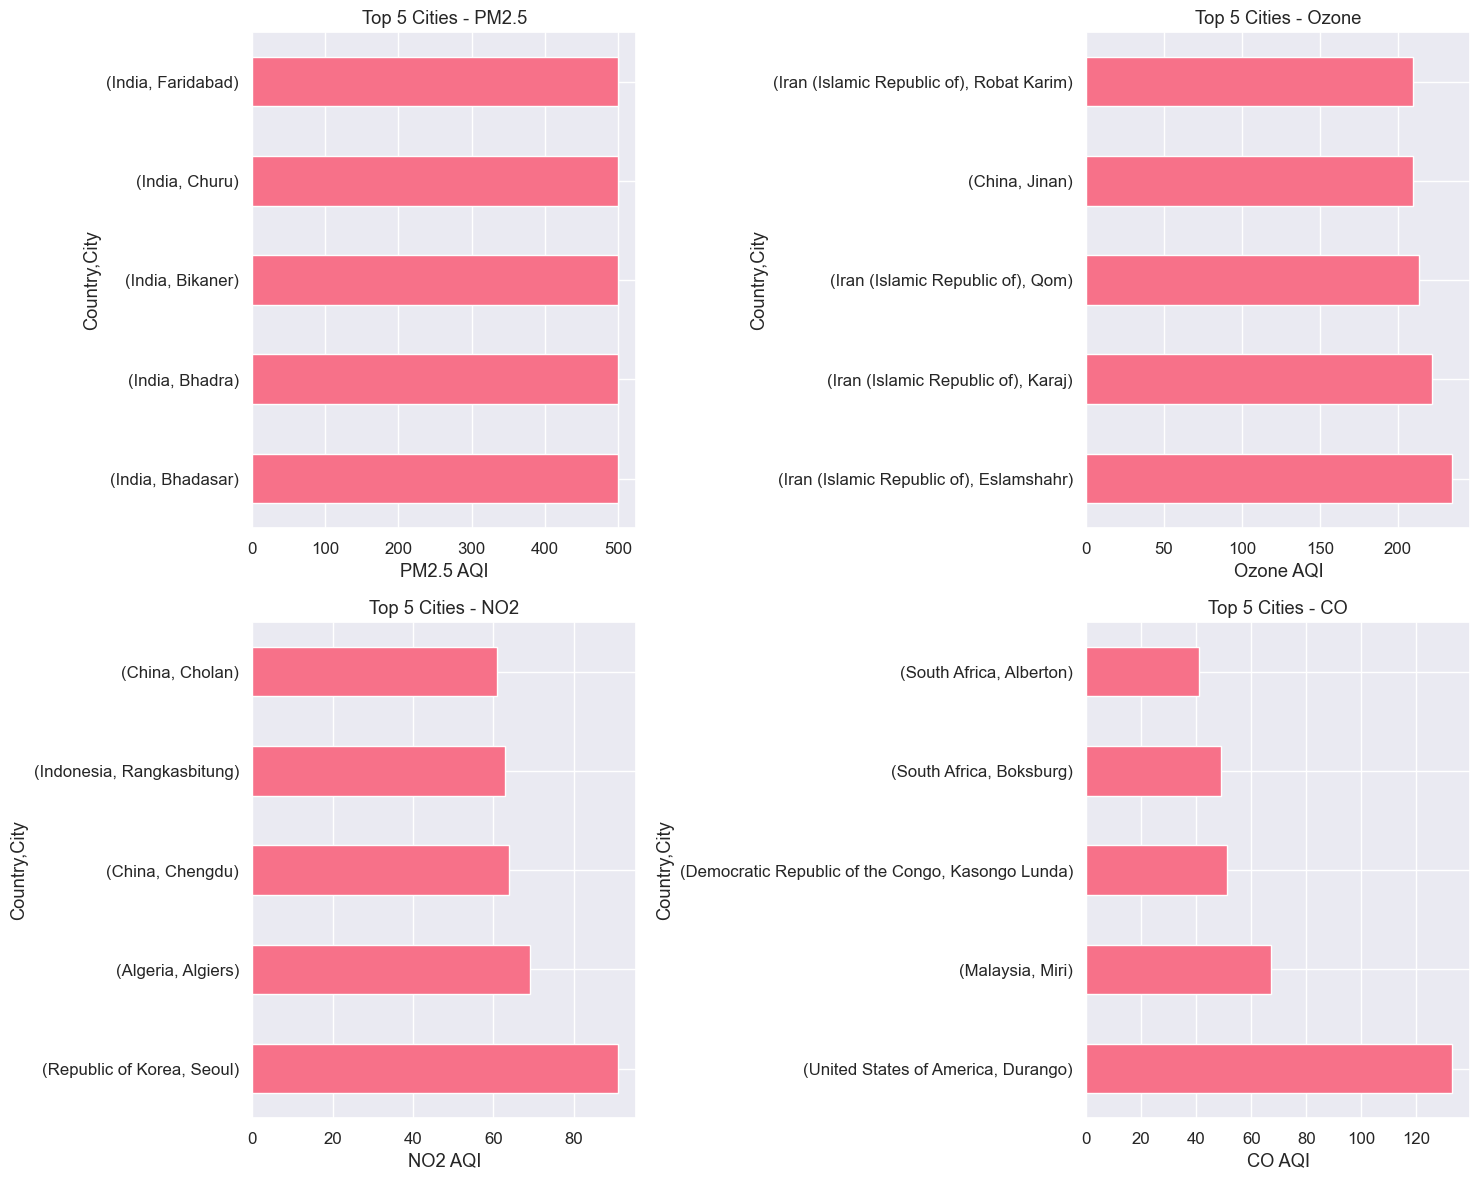

In [29]:
# 7. POLLUTANT-SPECIFIC TOP CITIES
#Question: Which cities are most affected by a specific pollutant (CO, Ozone, NO2, PM2.5)?
pollutants = {
    "PM2.5 AQI Value": "PM2.5", 
    "Ozone AQI Value": "Ozone", 
    "NO2 AQI Value": "NO2", 
    "CO AQI Value": "CO"
}

fig, axes = plt.subplots(2, 2, figsize=(15, 12))
axes = axes.flatten()
for i, (col, name) in enumerate(pollutants.items()):
    top_cities = df.groupby(["Country","City"])[col].mean().nlargest(5)
    top_cities.plot(kind='barh', ax=axes[i])
    axes[i].set_title(f"Top 5 Cities - {name}")
    axes[i].set_xlabel(name + " AQI")
plt.tight_layout()
plt.show()

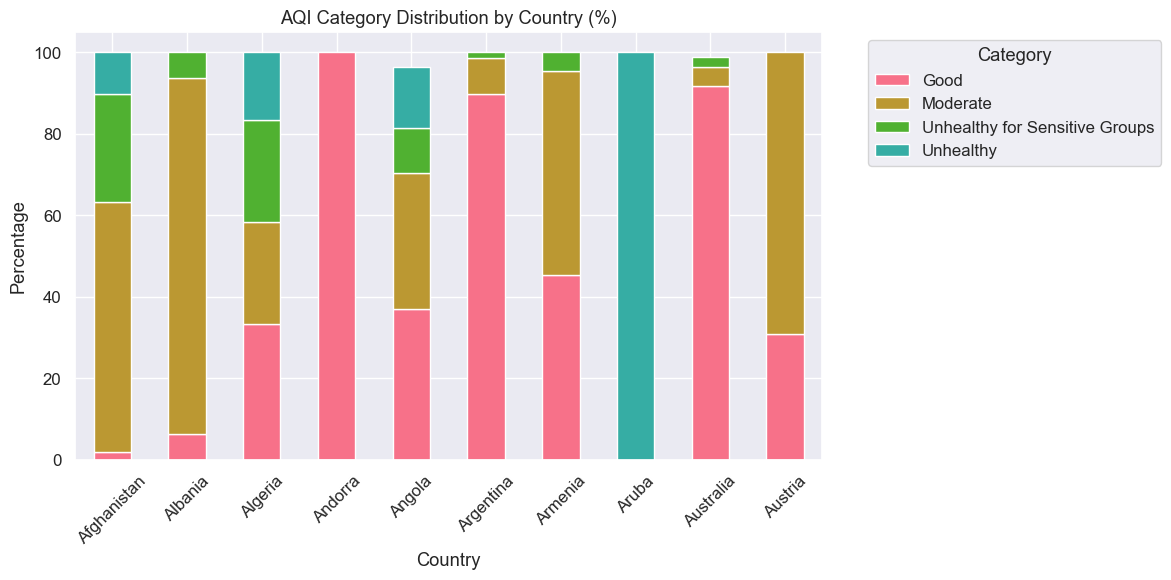

In [30]:
# 8. AQI CATEGORY % BY COUNTRY
#Question: How does AQI category distribution vary by country?
country_cat = df.groupby(['Country', 'AQI Category']).size().unstack(fill_value=0)
country_cat = country_cat.loc[:, ['Good', 'Moderate', 'Unhealthy for Sensitive Groups', 'Unhealthy']].div(country_cat.sum(axis=1), axis=0) * 100
country_cat.head(10).plot(kind='bar', stacked=True, figsize=(12, 6))
plt.ylabel("Percentage")
plt.title("AQI Category Distribution by Country (%)")
plt.legend(title="Category", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

 172 cities with HAZARDOUS PM2.5:
          Country          City  PM2.5 AQI Value
180         India    Govindgarh              307
276      Pakistan  Bahawalnagar              466
277  South Africa       Balfour              380
417         India      Phillaur              391
470         India         Rania              464
524         India        Gohana              500
598         India      Mainpuri              362
611         India       Gunnaur              500
620      Pakistan     Harunabad              443
644         India        Khetri              376


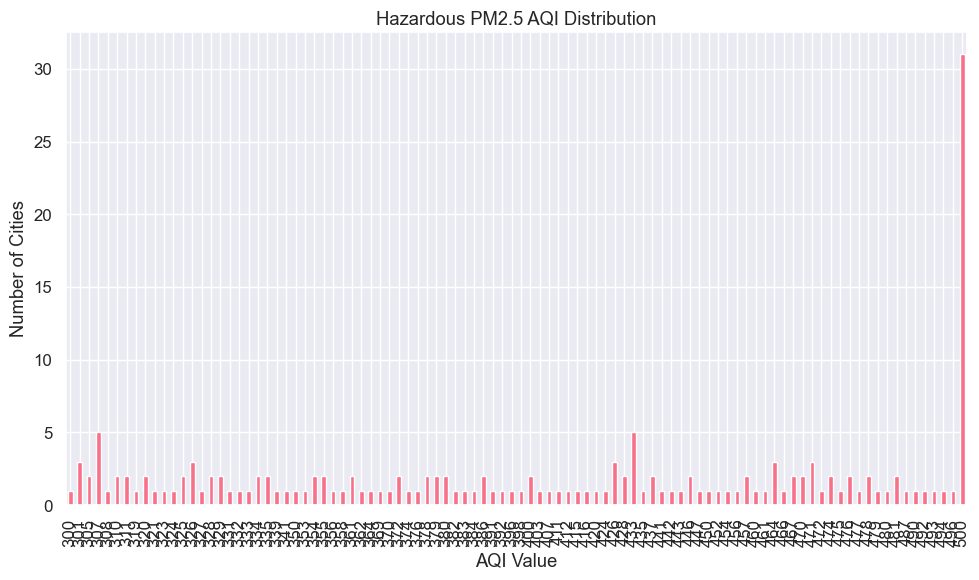

In [31]:
# 9. EXTREME PM2.5 HOTSPOTS (Hazardous cities)
#Question: Which cities fall under the “Hazardous” AQI Category for PM2.5?
hazardous_pm25 = df[df['PM2.5 AQI Category'] == 'Hazardous'][['Country', 'City', 'PM2.5 AQI Value']].drop_duplicates()
print(f" {len(hazardous_pm25)} cities with HAZARDOUS PM2.5:")
print(hazardous_pm25.head(10))

hazardous_pm25['PM2.5 AQI Value'].value_counts().sort_index().plot(kind='bar', figsize=(10, 6))
plt.title("Hazardous PM2.5 AQI Distribution")
plt.xlabel("AQI Value")
plt.ylabel("Number of Cities")
plt.tight_layout()
plt.show()

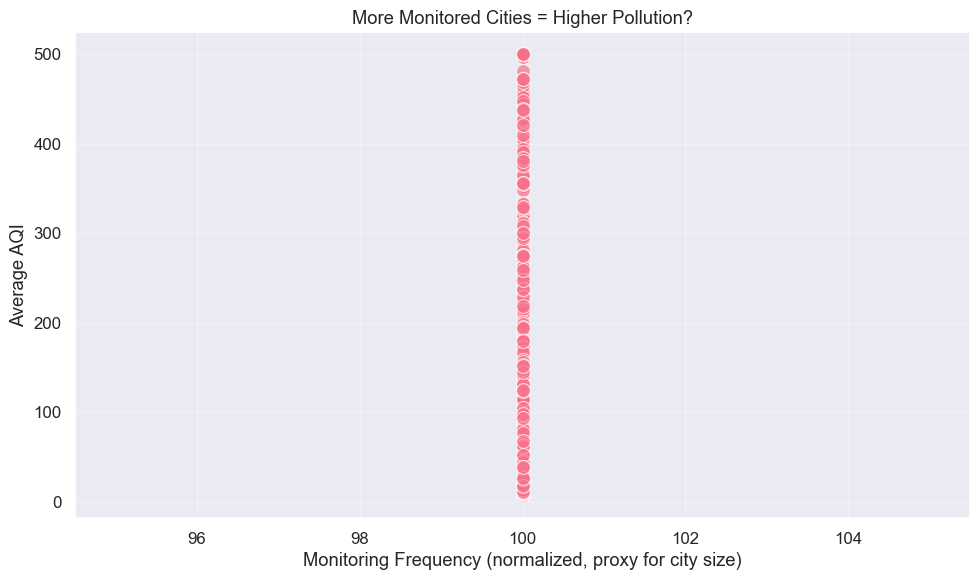

In [32]:
# 10. AQI vs CITY MONITORING FREQUENCY 
#Question: Does city size correlate with higher AQI levels?
city_freq = df.groupby('City').size().to_frame('Records').join(city_aqi, how='inner')
city_freq['Records'] = city_freq['Records'] / city_freq['Records'].max() * 100  # Normalize

plt.figure(figsize=(10, 6))
sns.scatterplot(data=city_freq, x='Records', y='AQI Value', alpha=0.7, s=100)
plt.xlabel("Monitoring Frequency (normalized, proxy for city size)")
plt.ylabel("Average AQI")
plt.title("More Monitored Cities = Higher Pollution?")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

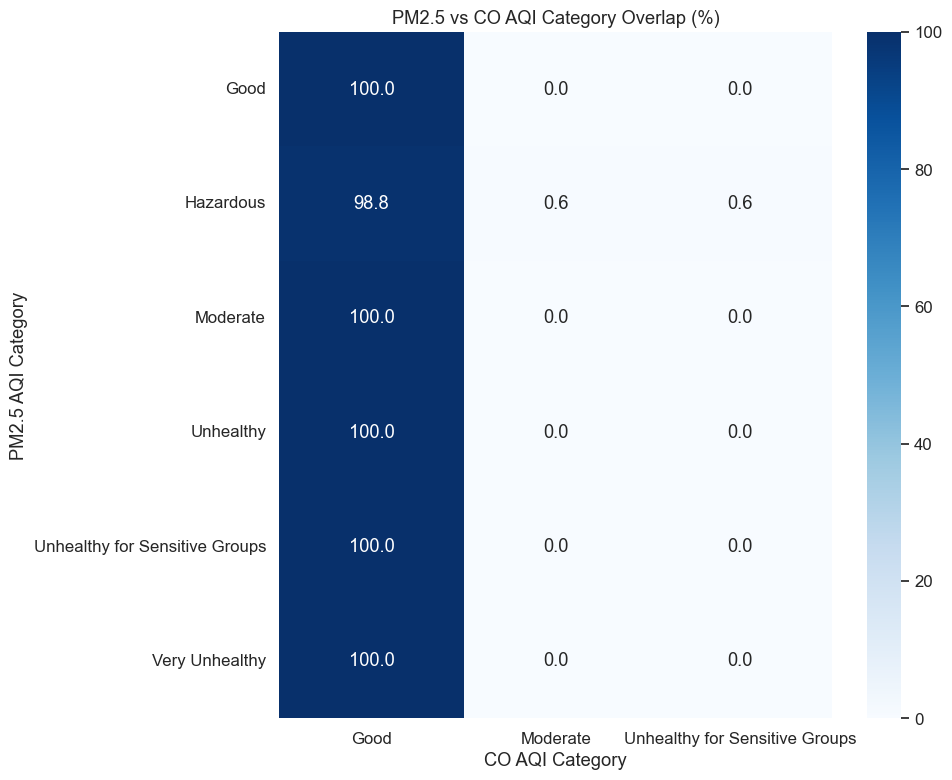

In [33]:
# 11. POLLUTANT CATEGORY OVERLAP
#Question: Do cities with high CO AQI also have high PM2.5 AQI?
overlap = pd.crosstab(df['PM2.5 AQI Category'], df['CO AQI Category'], normalize='index') * 100
plt.figure(figsize=(10, 8))
sns.heatmap(overlap, annot=True, fmt='.1f', cmap='Blues')
plt.title("PM2.5 vs CO AQI Category Overlap (%)")
plt.tight_layout()
plt.show()


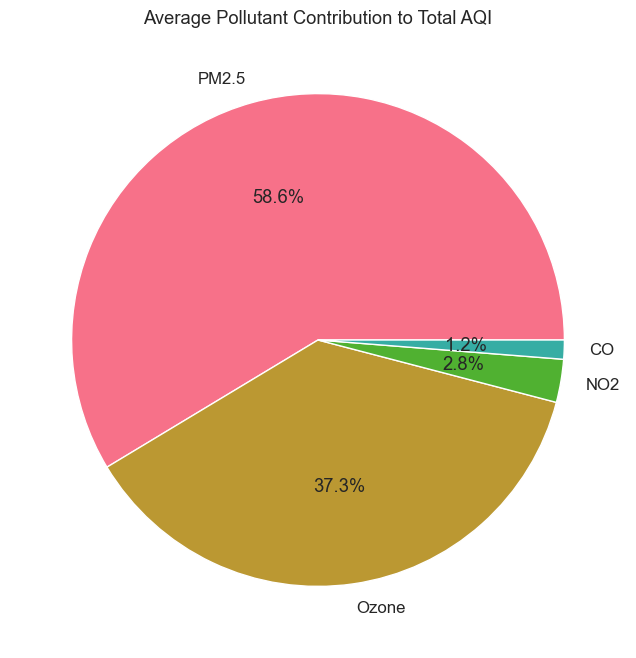

In [34]:
# 12. POLLUTANT CONTRIBUTION TO TOTAL AQI
#Question: Which pollutant contributes most to the overall AQI across cities?
df_pos = df[df['AQI Value'] > 0].copy()
contributions = {
    'PM2.5': (df_pos['PM2.5 AQI Value']/df_pos['AQI Value']).mean(),
    'Ozone': (df_pos['Ozone AQI Value']/df_pos['AQI Value']).mean(),
    'NO2': (df_pos['NO2 AQI Value']/df_pos['AQI Value']).mean(),
    'CO': (df_pos['CO AQI Value']/df_pos['AQI Value']).mean()
}

plt.figure(figsize=(8, 8))
plt.pie(contributions.values(), labels=contributions.keys(), autopct='%1.1f%%')
plt.title("Average Pollutant Contribution to Total AQI")
plt.show()